# Ce Notebook contient les principales étapes de l'analyse ainsi que les résultats

*Projet Python pour la Data Science — Elisa Desloges, Maxime Girard, Amélie Thiebot — 2026*

## Introduction

3,5 % : c’est la part de la population qu’il faudrait pour faire tomber n’importe quel gouvernement.

Cette règle a été théorisée par la chercheuse américaine Erica Chenoweth et sa consœur Maria J. Stephan en 2013 dans *Why Civil Resistance Works*. En étudiant 323 mouvements de contestation entre 1900 et 2006, les chercheuses ont observé qu'aucun gouvernement n'a résisté face à un mouvement civil non violent ayant réussi à mobiliser au moins 3,5 % de la population de son pays au plus fort de la crise.

Dans le contexte actuel de mobilisations en Europe, nous avons décidé de mettre à l’épreuve cette règle et d’analyser ce qui fait qu’un mouvement réussit ou non.

c

## Sommaire

- I. Importation des modules
- II. Importation des bases de données
    - Données et préparation
    - Variables construites
- III. Nettoyage et fusion des deux bases de données
- IV. Lien entre taux de participation et réussite du mouvement
    - Calcul de la corrélation de Spearman
    - Issue de chaque campagne
    - Prise en compte uniquement du pic de participation
    - Seuil de 3,5% et déciles de pourcentage de participation 
    - Graphiques : succès d'un mouvement selon le pic de participation
    - Focus sur les mouvements non-violents
    - Graphiques : succès des mouvements non-violents en fonction du pic de participation
- V. Etude de la violence
    - Classification des campagnes
    - Issue de chaque campagne
    - Méthode et succès
    - Etude d'un lien entre objectif de la mobilisation et violence
    - Analyse de la branche radicale au sein des campagnes non violentes

- Conclusions

## I. Importation des modules

Pour lire le fichier .xls, pandas utilise le moteur calamine.

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import nbformat as nb
import statsmodels.miscmodels.ordinal_model as stm

## II. Importation des bases de données

In [60]:
# Importation de la base 1 (NAVCO 2.1)
navco = pd.read_excel("Data/base2-1.xls")

# Importation de la base de population
pop = pd.read_csv("Data/population.csv", sep=",")

data_clean = False

Pour examiner la règle de Erica Chenoweth, nous avons utilisé deux bases de données.
- la base NAVCO 2.1 (Nonviolent and Violent Campaigns and Outcomes) recense 384 campagnes de résistance, observées année par année de 1945 à 2013, soit 2 717 observations campagne-année
- la base de population d'Our World in Data fournit la population de chaque pays à chaque année.

## III. Nettoyage et fusion des deux bases de données

### Données et préparation

Nous avons fusionné les deux bases de données à partir du nom du pays et de l'année. Les observations qui n'ont pas pu être appariées (18 sur 2 717) ont été examinées une à une, ce qui a permis de corriger la plupart des problèmes.

Plusieurs pays étaient écrits différemment dans les deux bases (par exemple « Myanmar/Burma » et « Myanmar », ou « Ivory Coast » et « Côte d'Ivoire »). Nous les avons harmonisés avec un dictionnaire de correspondances. Le cas de la Yougoslavie était un peu particulier car le pays change de nom pour devenir “Serbia and Montenegro” à partir de 1992 dans la base population.

Pour l'Allemagne de l'Est (1953 et 1989) et le Yémen du Nord (1962 à 1969), la base de population n'avait pas de valeur pour les années concernées. Nous avons utilisé la valeur de l'année disponible la plus proche (1950, 1990 et 1970 respectivement), en vérifiant que l'écart restait limité.

Le Sud-Vietnam et le Tibet ne figurent pas dans la base de population. Leurs observations ont donc un pourcentage de participation non calculable.

### Variables construites

La variable *total_part* contenait la valeur −99 pour les données manquantes que nous avons remplacée par une valeur manquante. Nous avons ensuite calculé le pourcentage de la population participant au mouvement chaque année (pourcent_part).

Pour éviter que des valeurs aberrantes biaisent notre analyse, nous avons examiné toutes les observations dépassant 20 % de la population (19 cas). Après vérification des sources, toutes celles dépassant 50 % provenaient d'erreurs de la base NAVCO (par exemple, 2 millions de participants pour 1,57 million d'habitants pour la « Singing Revolution » en Estonie). Elles ont été remplacées par des valeurs manquantes. Les valeurs entre 20 % et 50 % ont été conservées, car elles sont plausibles pour des mouvements de masse.

La variable *progress* est codée à l'origine ainsi : 0 = statu quo, 1 = gains visibles sans concessions, 2 = concessions limitées, 3 = concessions importantes, 4 = succès complet, 5 = échec. Pour obtenir une échelle ordonnée, nous avons recodé l'échec à la valeur la plus basse. La nouvelle variable progress2 va de 0 (échec) à 5 (succès complet).

Nous avons également créé un tableau où sont conservées uniquement les observations où le pourcentage de participation et la progression sont connus, soit 2 266 observations portant sur 364 campagnes.


In [61]:
if data_clean == False:
    with open("Cleanup.ipynb", "r", encoding="utf-8") as f:
        cleanup_nb = nb.read(f, as_version=4)

    # Use the current notebook's namespace
    namespace = globals()

    # Execute all code cells sequentially
    for cell in cleanup_nb.cells:
        if cell.cell_type == "code":
            exec(cell.source, namespace)  # noqa: S102
    
    data_clean = True

2717 2717
_merge
both          2699
left_only       18
right_only       0
Name: count, dtype: int64
     location  year
South Vietnam  1958
South Vietnam  1959
South Vietnam  1960
South Vietnam  1961
South Vietnam  1962
South Vietnam  1963
South Vietnam  1964
South Vietnam  1965
South Vietnam  1966
        Tibet  1956
        Tibet  1957
        Tibet  1958
        Tibet  1959
        Tibet  1987
        Tibet  1988
        Tibet  1989
      location  year  total_part_clean  Population  pourcent_part
0   Madagascar  1991          400000.0  12421413.0       3.220246
1   Madagascar  1992               NaN  12800870.0            NaN
2   Madagascar  1993               NaN  13197353.0            NaN
3     Djibouti  1991            3000.0    631096.0       0.475363
4     Djibouti  1992            4500.0    626016.0       0.718831
5     Djibouti  1993            4500.0    614247.0       0.732604
6     Djibouti  1994            4500.0    626717.0       0.718027
7  Afghanistan  1979           1

## IV. Lien entre taux de participation et réussite du mouvement

### Calcul de la corrélation de Spearman

Pour commencer, nous avons étudié le lien entre le pourcentage de la population participant à un mouvement et sa progression (progress2, de 0 pour l'échec à 5 pour le succès complet), année par année. Dans cette analyse, chaque ligne correspond à une année d'une campagne : une campagne est donc comptée autant de fois qu'elle a duré d'années. Ce choix permet d'observer comment la progression évolue avec la participation au fil du temps, mais il a une limite : les observations d'une même campagne ne sont pas indépendantes, ce qui rend la p-value trop optimiste.

Nous avons utilisé la corrélation de Spearman, adaptée à une variable ordinale comme la progression et peu sensible aux valeurs extrêmes de participation. Nous obtenons un coefficient de 0,25 (p < 0,001) : la corrélation est positive et modérée, c'est-à-dire que les années où la participation est plus forte tendent à correspondre à une progression plus avancée.


In [62]:
spearman_corr, p_value = stats.spearmanr( df_pc_pop["pourcent_part"], df_pc_pop["progress2"]) # corrélation de Spearman

print(f"Corr de Spearman : {spearman_corr:.4f}") #ici on regarde année par année les mouvements donc certains sont représentés plusieurs fois
print(f"P-value : {p_value:.4e}")

Corr de Spearman : 0.2538
P-value : 1.2482e-34


Nous avons ensuite éliminé les campagnes encore en cours en 2013 afin de pouvoir analyser l’issue finale des mouvements (succès ou échec) par rapport au taux de participation.


In [63]:
fin = base.groupby("id").agg(succes=("success", "max"),
                             statut=("status", "last"))

issue = pd.Series(
    np.select([fin["succes"] == 1, fin["statut"] == 0], ["succes", "echec"], default="en_cours"),
    index=fin.index)

ids_finis = issue[issue != "en_cours"].index
navco_pop_f = navco_pop[navco_pop["id"].isin(ids_finis)].copy() #on exclut les campagnes encore en cours
print("Campagnes en cours (exclues) :", (issue == "en_cours").sum())

Campagnes en cours (exclues) : 53


### Prise en compte uniquement du pic de participation

Pour que chaque mouvement ne soit compté qu'une seule fois, nous avons regroupé les observations par identifiant de campagne. Chaque mouvement est alors résumé par deux informations : son pic de participation (part maximale de la population mobilisée au cours de la campagne) et son issue, codée 1 en cas de succès et 0 en cas d'échec. Nous avons retenu le pic plutôt que la moyenne, car il reflète la capacité maximale de mobilisation du mouvement, quelle que soit la durée de la campagne. Les mouvements pour lesquels aucun pourcentage de participation n'est calculable (participation inconnue, population absente de la base ou valeur aberrante supprimée) ont été retirés de cette analyse.

In [64]:
mouv_peak = (
    navco_pop_f.sort_values(["id", "year"])
    .groupby("id")
    .agg(
        location=("location", "first"),
        pic_pourcent=("pourcent_part", "max"),      # pic de participation
        success=("success", "last"),                # dernière ligne = résultat final
    )
    .reset_index()
)

print(mouv_peak.shape)                      

print("Mouvements sans pic calculable :", mouv_peak["pic_pourcent"].isna().sum())

(331, 4)
Mouvements sans pic calculable : 19


### Seuil de 3,5% et déciles de pourcentage de participation 

Pour visualiser l’effet de la participation, nous avons réparties les campagnes en dix classes de même effectif selon leur pic de participation. Le taux de succès augmente nettement avec la participation : il est de 9 % pour la classe la moins mobilisée et de 72 % pour la plus mobilisée. La hausse est rapide au début, puis le taux se stabilise autour de 50 à 60 % pour des pics compris entre 0,3 % et 5 % de la population. Le lien est donc croissant mais ne présente pas de rupture nette.

Nous avons ensuite comparé les campagnes selon qu'elles ont atteint ou non 3,5 % de la population, le seuil de la règle de Chenoweth. Parmi les 40 campagnes qui l'ont atteint, 27 ont réussi (67,5 %), contre 112 sur 272 (41,2 %) pour celles qui sont restées en dessous. Un test exact de Fisher confirme que cet écart n'est pas dû au hasard. La côte de succès (rapport succès/échecs) est environ trois fois plus élevée au-dessus du seuil (odds ratio = 2,97, p = 0,002). 

Ce résultat va dans le sens de la règle de Chenoweth sans la valider telle quelle. Au-dessus du seuil, 13 campagnes sur 40 ont échoué. La participation ne garantit donc pas le succès. On suppose que d'autres facteurs, comme la réponse du pouvoir en place ou le contexte international (l'occupation soviétique en Tchécoslovaquie, par exemple), interviennent.


In [65]:
mouv_peak = mouv_peak.dropna(subset=["pic_pourcent"]).copy()    
mouv_peak["tranche"] = pd.qcut(mouv_peak["pic_pourcent"], q=10, duplicates="drop")
print(mouv_peak.groupby("tranche", observed=True)["success"].agg(n="count", taux="mean"))

mouv_peak["au_dessus"] = mouv_peak["pic_pourcent"] >= 3.5
print(mouv_peak.groupby("au_dessus")["success"].agg(n="count", taux="mean"))
print(mouv_peak[(mouv_peak["au_dessus"]) & (mouv_peak["success"] == 0)])   # les exceptions

ct0 = pd.crosstab(mouv_peak["au_dessus"], mouv_peak["success"])
print(ct0)
odds, p = stats.fisher_exact(ct0)
print(f"Odds ratio = {odds:.2f}, p = {p:.2e}")

                      n      taux
tranche                          
(-0.000414, 0.0236]  32  0.093750
(0.0236, 0.056]      31  0.258065
(0.056, 0.125]       31  0.354839
(0.125, 0.191]       31  0.322581
(0.191, 0.337]       31  0.451613
(0.337, 0.627]       31  0.612903
(0.627, 0.959]       31  0.548387
(0.959, 1.965]       31  0.516129
(1.965, 4.897]       31  0.580645
(4.897, 32.581]      32  0.718750
             n      taux
au_dessus               
False      272  0.411765
True        40  0.675000
      id                      location  pic_pourcent  success  \
18    21                      Pakistan      4.276359        0   
21    24                        Panama     32.580662        0   
57    64                Czechoslovakia     24.441341        0   
65    74                  East Germany     10.875476        0   
74    83                    Madagascar      5.356130        0   
160  184           Yemen Arab Republic      4.508197        0   
165  189  Democratic Republic of Cong

### Graphiques : succès d'un mouvement selon le pic de participation

Pour visualiser ces résultats, nous avons représenté le taux de succès sous et au-dessus du seuil de 3,5 % (figure 1), puis selon six classes de participation (figure 2). Le taux de succès est de 21 % pour les campagnes qui mobilisent moins de 0,1 % de la population, de 44 % entre 0,1 et 0,5 %, de 58 % entre 0,5 et 1 %, de 55 % entre 1 et 3,5 %, de 68 % entre 3,5 et 10 % et de 67 % au-delà de 10 %. 

La progression est donc la plus marquée aux faibles niveaux de participation et se ralentit ensuite. Cette configuration suggère un effet progressif de la participation plutôt qu'un seuil net à 3,5 %, même si l'écart observé de part et d'autre de ce seuil reste statistiquement significatif. 

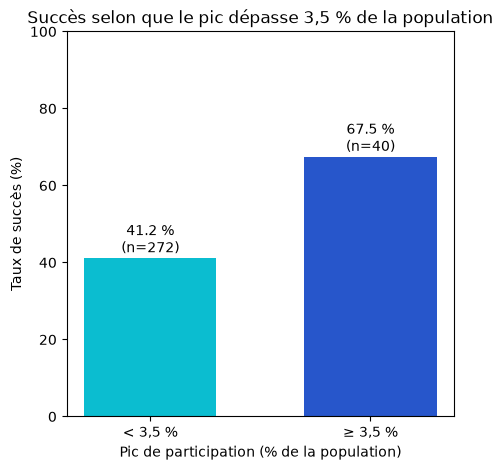

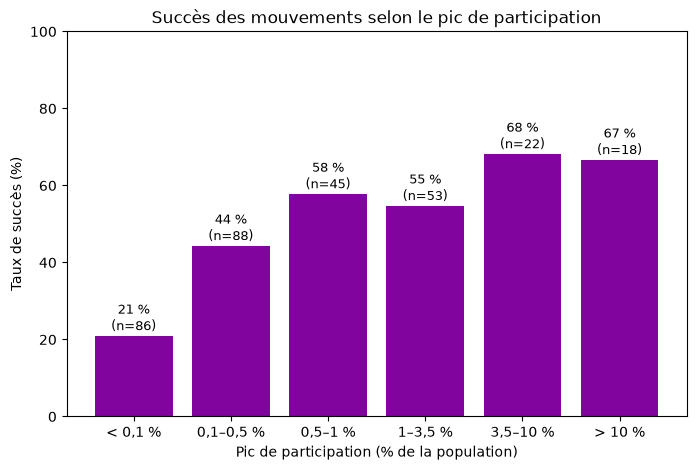

In [66]:
tab1 = mouv_peak.groupby("au_dessus")["success"].agg(n="count", taux="mean")
labels = ["< 3,5 %", "≥ 3,5 %"]          # False puis True, dans cet ordre

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(labels, tab1["taux"] * 100, color=["#0BBDD0", "#2756CB"], width=0.6)

for i, (t, n) in enumerate(zip(tab1["taux"], tab1["n"])):  #pour afficher l'effectif de chaque barre
    ax.text(i, t * 100 + 1.5, f"{t*100:.1f} %\n(n={n})", ha="center", fontsize=10)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès selon que le pic dépasse 3,5 % de la population")
ax.set_ylim(0, 100)
plt.savefig("Graphiques/graph_seuil_3_5.png", dpi=200, bbox_inches="tight")
plt.show()

bins   = [0, 0.1, 0.5, 1, 3.5, 10, 35]
labels = ["< 0,1 %", "0,1–0,5 %", "0,5–1 %", "1–3,5 %", "3,5–10 %", "> 10 %"]

mouv_peak["classe"] = pd.cut(mouv_peak["pic_pourcent"], bins=bins,
                             labels=labels, include_lowest=True)
tab2 = mouv_peak.groupby("classe", observed=True)["success"].agg(n="count", taux="mean")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tab2.index, tab2["taux"] * 100, color="#82049E")
for i, (t, n) in enumerate(zip(tab2["taux"], tab2["n"])):
    ax.text(i, t * 100 + 1.5, f"{t*100:.0f} %\n(n={n})", ha="center", fontsize=9)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès des mouvements selon le pic de participation")
ax.set_ylim(0, 100)
plt.savefig("Graphiques/graph_participation_succes.png", dpi=200, bbox_inches="tight")
plt.show()

### Focus sur les mouvements non-violents

L’étude de la chercheuse Erica Chenoweth et le résultat de 3,5 % évoquent uniquement les mouvements non violents. Il nous a donc été nécessaire de se concentrer sur les mouvements pacifiques afin d’y faire les mêmes analyses. 

Pour ce faire, nous avons classé chaque campagne selon sa méthode dominante : elle est considérée comme non violente lorsque la majorité de ses années d'observation relèvent de méthodes non violentes. Cette classification a été rattachée à la table des campagnes (mouv_peak) par leur identifiant. Parmi les 312 campagnes terminées dont le pic de participation est connu, 142 sont majoritairement non violentes.

Parmi les mouvements non violents, 29 ont atteint 3,5 % de la population. Leur taux de succès est de 75,9 % contre 55,8 % pour ceux restés sous le seuil, soit un écart de 20 points. La côte de succès (rapport succès/échecs) est environ 2,5 fois plus élevée au-dessus du seuil (odds ratio = 2,49). Toutefois, cette différence n'est pas statistiquement significative au seuil de 5 % (test exact de Fisher, p = 0,057). Avec seulement 29 mouvements au-dessus du seuil, le test manque de puissance.

La proportion de mouvements réussis parmi les mouvements qui mobilisent 3,5% de la population est plus élevée si on regarde uniquement les mouvements pacifiques. Cependant, il reste des exceptions et il n’y a pas de raison évidente de prendre le seuil de 3,5 % comme règle absolue. Le résultat est cohérent avec la règle de Chenoweth, mais il ne suffit pas à la confirmer. Une forte participation n'est pas, à elle seule, une garantie de succès et il est difficile de poser une règle aussi stricte sur des mouvements sociaux et politiques variés.


In [67]:
camp0 = (navco2.groupby("id")
        .agg(violente_moy=("violente", "mean"))
        .reset_index())
camp0["violente"] = (camp0["violente_moy"] > 0.5).astype(int)

mouv_peak = mouv_peak.merge(camp0[["id", "violente"]], on="id", how="left") #on ajoute la variable violence au mouv_peak

# Garder uniquement les mouvements non violents
mouv_peak2 = mouv_peak[mouv_peak["violente"] == 0].copy()
print(mouv_peak2.shape)

mouv_peak2["au_dessus"] = mouv_peak2["pic_pourcent"] >= 3.5
print(mouv_peak2.groupby("au_dessus")["success"].agg(n="count", taux="mean"))
print(mouv_peak2[(mouv_peak2["au_dessus"]) & (mouv_peak2["success"] == 0)])   # les exceptions

ct02 = pd.crosstab(mouv_peak2["au_dessus"], mouv_peak2["success"])
print(ct02)
odds, p = stats.fisher_exact(ct02)
print(f"Odds ratio = {odds:.2f}, p = {p:.2e}")

(142, 8)
             n      taux
au_dessus               
False      113  0.557522
True        29  0.758621
      id        location  pic_pourcent  success          tranche  au_dessus  \
17    21        Pakistan      4.276359        0   (1.965, 4.897]       True   
20    24          Panama     32.580662        0  (4.897, 32.581]       True   
55    64  Czechoslovakia     24.441341        0  (4.897, 32.581]       True   
63    74    East Germany     10.875476        0  (4.897, 32.581]       True   
221  266        Honduras      5.976657        0  (4.897, 32.581]       True   
253  310           Tonga      4.731085        0   (1.965, 4.897]       True   
277  367         Comoros     26.590505        0  (4.897, 32.581]       True   

       classe  violente  
17   3,5–10 %         0  
20     > 10 %         0  
55     > 10 %         0  
63     > 10 %         0  
221  3,5–10 %         0  
253  3,5–10 %         0  
277    > 10 %         0  
success     0   1
au_dessus        
False      50 

Les mouvements non violents ont mobilisé davantage. Leur pic médian de participation est de 0,75 % de la population contre 0,18 % pour les mouvements violents. 

In [68]:
# Pic de participation médian selon la méthode
print(mouv_peak.groupby("violente")["pic_pourcent"].median())

violente
0    0.751990
1    0.181965
Name: pic_pourcent, dtype: float64


### Graphiques : succès des mouvements non-violents en fonction du pic de participation

Nous représentons ces nouveaux résultats dans des graphiques similaires aux précédents. Encore une fois, la hausse la plus nette a lieu autour de 0,5 % de la population. 

Ces résultats vont dans le sens de la règle de Chenoweth. Les mouvements non violents très mobilisés réussissent plus souvent. Mais ils ne permettent pas de confirmer un effet propre au seuil de 3,5 %, qui ne se détache pas nettement des niveaux de participation inférieurs.

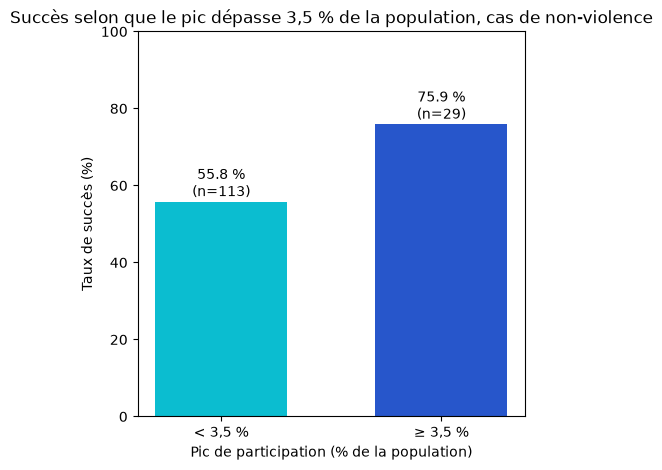

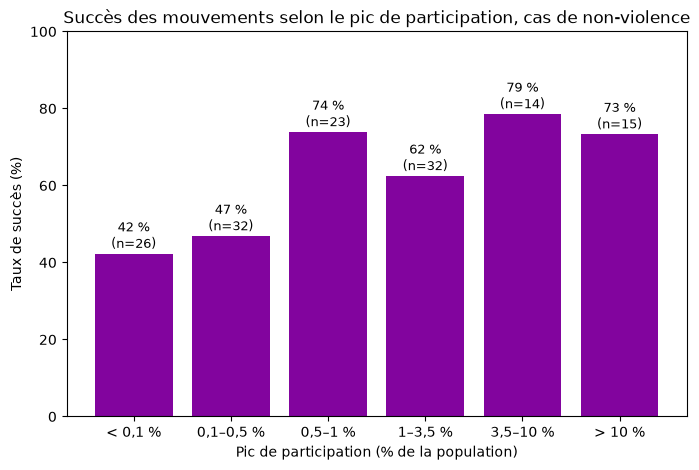

In [69]:
tab3 = mouv_peak2.groupby("au_dessus")["success"].agg(n="count", taux="mean")
labels = ["< 3,5 %", "≥ 3,5 %"]          # False puis True, dans cet ordre

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(labels, tab3["taux"] * 100, color=["#0BBDD0", "#2756CB"], width=0.6)

for i, (t, n) in enumerate(zip(tab3["taux"], tab3["n"])):  #pour afficher l'effectif de chaque barre
    ax.text(i, t * 100 + 1.5, f"{t*100:.1f} %\n(n={n})", ha="center", fontsize=10)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès selon que le pic dépasse 3,5 % de la population, cas de non-violence")
ax.set_ylim(0, 100)
plt.savefig("Graphiques/graph_seuil_3_5.nonviolent.png", dpi=200, bbox_inches="tight")
plt.show()

bins   = [0, 0.1, 0.5, 1, 3.5, 10, 35]
labels = ["< 0,1 %", "0,1–0,5 %", "0,5–1 %", "1–3,5 %", "3,5–10 %", "> 10 %"]

mouv_peak2["classe"] = pd.cut(mouv_peak2["pic_pourcent"], bins=bins,
                             labels=labels, include_lowest=True)
tab4 = mouv_peak2.groupby("classe", observed=True)["success"].agg(n="count", taux="mean")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tab4.index, tab4["taux"] * 100, color="#82049E")
for i, (t, n) in enumerate(zip(tab4["taux"], tab4["n"])):
    ax.text(i, t * 100 + 1.5, f"{t*100:.0f} %\n(n={n})", ha="center", fontsize=9)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès des mouvements selon le pic de participation, cas de non-violence")
ax.set_ylim(0, 100)
plt.savefig("Graphiques/graph_participation_succes_nonviolent.png", dpi=200, bbox_inches="tight")
plt.show()


Ainsi, notre analyse des données va dans le sens de la règle de Erica Chenoweth. La réussite d'un mouvement augmente avec le taux de participation et la grande majorité des mouvements pacifiques qui dépassent le seuil de 3,5 % de participation réussissent. Cependant, nous ne voyons pas de raison évidente de prendre ce seuil comme une règle stricte car la hausse la plus nette se réalisent davantage dans des seuils plus bas (autour de 0,5 %) et qu'aucun seuil ne permet d'avoir un taux de réussite proche de 100 %. Un plus grand nombre de données pourrait peut-être préciser ce seuil. 

Il est important de noter que d'autres facteurs entrent en jeu pour expliquer l'issue des mouvements sociaux et politiques. Dans la partie suivante, nous étudierons les effets de la violence sur succès des mobilisations.

## V. Etude de la violence

Dans cette partie, nous allons étudier la violence au sein des mobilisations. La partie précédente a montré que la violence modifie l'effet de la participation sur le succès. Mais qu'en est-il de la violence au sens large ? Un mouvement a-t-il plus de chance de réussir s'il est dépourvu de violence ?


### Classification des campagnes

Nous attribuons à chaque campagne une catégorie unique (méthode dominante, changement de méthode éventuel) afin de pouvoir comparer les taux de succès entre groupes.

*flank_max* correspond au maximum sur toutes les années. Une campagne avec une seule année de violence létale est classée 3.

In [70]:
camp = (navco2.groupby("id")
        .agg(camp_name=("camp_name", "first"),
             location=("location", "first"),
             violente_moy=("violente", "mean"))
        .reset_index())
camp["violente"] = (camp["violente_moy"] > 0.5).astype(int)
camp["mixte"] = camp["violente_moy"].between(0.01, 0.99)
camp["flank_max"] = camp["id"].map(navco2.groupby("id")["flank_intensity"].max())
camp["objectif"] = camp["id"].map(navco2.groupby("id")["camp_goals"].first())

### Issue de chaque campagne

Comme précédemment, nous retenons uniquement les campagnes dont l'issue est connue, en excluant celles encore en cours

In [71]:
derniere = navco2.groupby("id").tail(1).set_index("id")
camp["annee_finale"] = camp["id"].map(derniere["year"])
camp["progress_final"] = camp["id"].map(derniere["progress2"])
camp["status"] = camp["id"].map(derniere["status"])
camp["success"] = camp["id"].map(navco2.groupby("id")["success"].max())

camp["issue"] = np.select(
    [camp["success"] == 1, camp["status"] == 0],
    ["succes", "echec"],
    default="en_cours")

### Méthode et succès

Nous comparons le taux de succès des campagnes violentes et non violentes, en indiquant les effectifs.
Les campagnes en cours sont exclues parce que leur issue n'est pas encore connue, et les compter comme des échecs ferait baisser artificiellement le taux de succès.

In [72]:
camp_finie = camp[camp["issue"] != "en_cours"].copy()

print("Campagnes au total :", len(camp))
print("Campagnes en cours (exclues) :", (camp["issue"] == "en_cours").sum())
print("Campagnes retenues :", len(camp_finie))
print("dont mixtes :", camp_finie["mixte"].sum())

Campagnes au total : 384
Campagnes en cours (exclues) : 53
Campagnes retenues : 331
dont mixtes : 21


Nous avons donc un total de 384 campagnes dont 53 encore en cours que nous excluons donc. Parmi ces campagnes, 21 ont changé de méthode. Nous comparons maintenant le taux de succès des campagnes violentes et non violentes (graphique).


            taux  succes    n
violente                    
0         0.592      87  147
1         0.326      60  184


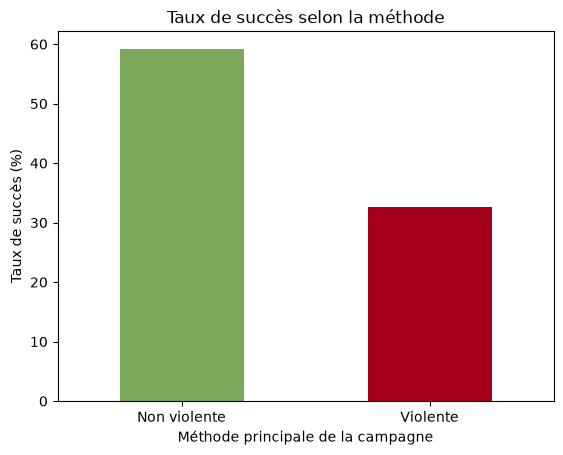

In [73]:
tab = camp_finie.groupby("violente")["success"].agg(taux="mean", succes="sum", n="count").round(3)
print("\n", tab)

camp_finie["methode"] = camp_finie["violente"].map({0: "Non violente", 1: "Violente"})

(camp_finie.groupby("methode")["success"].mean() * 100).plot(kind="bar", color=["#7AA95C", "#A7001E"])
plt.xlabel("Méthode principale de la campagne")
plt.ylabel("Taux de succès (%)")
plt.title("Taux de succès selon la méthode")
plt.xticks(rotation=0)
plt.savefig("Graphiques/graph_succes_methode.png", dpi=200, bbox_inches="tight")
plt.show()

Sur les 331 campagnes dont l'issue est connue, 59 % des campagnes non violentes ont atteint leur objectif maximaliste (87 sur 147), contre 33 % des campagnes violentes (60 sur 184). Nous constatons un écart d'environ 27 points de pourcentage : les campagnes non violentes semblent réussir presque deux fois plus souvent que les campagnes violentes.

On constate donc une corrélation entre la non-violence et la réussite de la campagne. Cependant, il ne s’agit pas nécessairement d’un lien de causalité. La violence et le succès peuvent être liée au type de régime, aux objectifs visés ou encore à la répression. Comme vu dans la partie IV sur les liens entre le taux de participation et la réussite, les mouvements non-violents réunissent davantage de personnes (pic de participation médian plus élevé). Cela peut être une des explications de la plus grande réussite des campagnes pacifiques. Dans la partie suivante, nous étudierons l'hypothèse selon laquelle l'écart de succès entre les méthodes violentes et non violentes s'expliquerait par l'objectif de la mobilisation.

Une autre limite que nous pouvons déjà mettre en avant à ce stade est l'exclusion des campagnes en cours. 53 campagnes sont exclues, car leur issue est inconnue, ce qui correspond à 13,8% de nos données.

In [74]:
ct = pd.crosstab(camp_finie["violente"], camp_finie["success"])
print("\n", ct)
odds, p = stats.fisher_exact(ct)
print(f"\nOdds ratio = {odds:.2f}, p = {p:.2e}")


 success     0   1
violente         
0          60  87
1         124  60

Odds ratio = 0.33, p = 1.56e-06


Le test exact de Fisher donne un odds ratio de 0,33. Les mobilisations violentes ont des chances de succès environ trois fois plus faibles en termes de cotes. 
La p-value (p ≈ 1,6e-06) très faible signifie qu'un écart de cette taille serait très improbable si la méthode n'avait aucun lien avec le succès.

Ainsi, la méthode employée lors des mobilisations est fortement associée à la réussite. Ce résultat va dans le sens des travaux de Chenoweth et Stephan, avec des taux du même ordre que ceux qu'ils rapportent.

### Etude d'un lien entre objectif de la mobilisation et violence

Dans la partie précédente, nous avons constaté un lien entre méthode et succès. Nous avions soulevé des limites et notamment le fait que ce lien pourrait s'expliquer par d'autres variables. Notre hypothèse était que selon l'objectif visé par la mobilisation, le moyen pourrait être différent. L'objectif expliquerait alors l'écart de succès entre les méthodes violentes et non violentes.
 
Pour cette partie, nous avons compté pour chaque campagne le nombre d'objectifs différents au fil des années. Nous avons trouvé que 49 campagnes changent au moins une fois d'objectif (soit environ 13 %). Nous avons donc sélectionné l'objectif de la première année pour ces mobilisations.

In [75]:
d = camp_finie.copy()
d["objectif"] = d["objectif"].replace(-99, np.nan)
d = d.dropna(subset=["objectif"])
d["objectif"] = d["objectif"].map({0: "Changement de régime", 1: "Réforme institutionnelle",
                                   2: "Changement de politique", 3: "Sécession",
                                   4: "Autonomie accrue", 5: "Opposition à l'occupation"})

print(pd.crosstab(d["objectif"], d["methode"], margins=True))
print(pd.crosstab(d["objectif"], d["methode"], normalize="index").round(2))
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(d["objectif"], d["methode"]))
print(f"Khi-deux : p = {p:.2e}")

print(d.groupby("objectif")["success"].agg(taux="mean", n="count").round(3)) # objectifs et succès

methode                    Non violente  Violente  All
objectif                                              
Autonomie accrue                      5         9   14
Changement de politique              16         9   25
Changement de régime                100        96  196
Opposition à l'occupation             6        32   38
Réforme institutionnelle             13         6   19
Sécession                             7        32   39
All                                 147       184  331
methode                    Non violente  Violente
objectif                                         
Autonomie accrue                   0.36      0.64
Changement de politique            0.64      0.36
Changement de régime               0.51      0.49
Opposition à l'occupation          0.16      0.84
Réforme institutionnelle           0.68      0.32
Sécession                          0.18      0.82
Khi-deux : p = 9.99e-07
                            taux    n
objectif                             
Auton

Les objectifs des mobilisations semblent fortement associés à la méthode employée (violence ou non violence). 84 % des campagnes d'opposition à l'occupation et 82 % des campagnes de sécession sont violentes, contre 32 % des campagnes de réforme institutionnelle (test du khi-deux, p < 0,001). Les objectifs pourraient donc expliquer une partie de l'écart de succès que nous avions trouvé dans la partie précédente entre les différentes méthodes. Pour le vérifier, nous avons estimé un modèle logistique du succès incluant la méthode et l'objectif.

In [76]:
# Odds ratio brut
tab = pd.crosstab(d["violente"], d["success"])
print("Brut :", round(stats.fisher_exact(tab)[0], 2))

# Odds ratio ajusté
haut, bas = 0, 0
for obj, g in d.groupby("objectif"):
    a = ((g["violente"] == 1) & (g["success"] == 1)).sum()
    b = ((g["violente"] == 1) & (g["success"] == 0)).sum()
    c = ((g["violente"] == 0) & (g["success"] == 1)).sum()
    e = ((g["violente"] == 0) & (g["success"] == 0)).sum() 
    haut += a * e / len(g)
    bas += b * c / len(g)
print("Ajusté sur l'objectif :", round(haut / bas, 2))

Brut : 0.33
Ajusté sur l'objectif : 0.34


L'odds ratio associé à la violence est environ 0,33, ce qui correspond à l'odds ratio brut. A objectif comparable, les campagnes violentes ont des cotes de succès environ trois fois plus faibles. L'écart entre campagnes violentes et non violentes ne s'explique donc pas par les objectifs visés.
Il reste tout de même une nuance à apporter. Nous avons vu au début que pour 13% des campagnes, l'objectif retenu est l'objectif initial. De plus, plusieurs catégories sont petites et d'autres facteurs qui peuvent aussi avoir un effet ne sont pas mesurés (type de régime).

### Analyse de la branche radicale au sein des campagnes non violentes

Dans cette partie, nous avons souhaité interroger la branche radicale dans un mouvement non violent. Cette branche change-t-elle le succès des campagnes non violentes ?

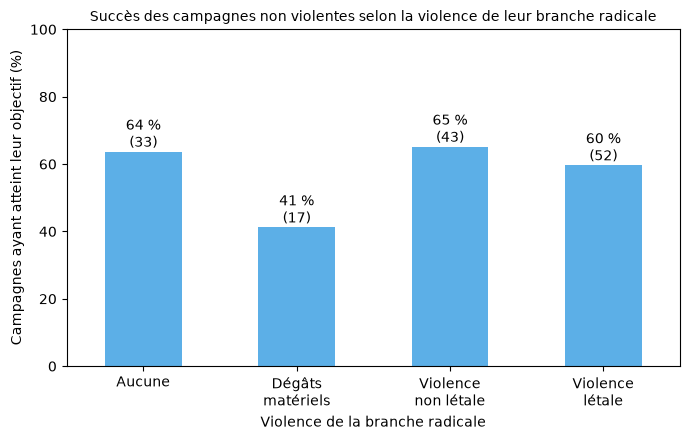

In [77]:
nv = camp_finie[camp_finie["violente"] == 0].copy()

label = {0: "Aucune", 1: "Dégâts\nmatériels", 2: "Violence\nnon létale", 3: "Violence\nlétale"}
nv["branche"] = nv["flank_max"].map(label)

ordre = list(label.values())
taux = nv.groupby("branche")["success"].mean().reindex(ordre) * 100
effectifs = nv.groupby("branche")["success"].count().reindex(ordre)

ax = taux.plot(kind="bar", color="#5CAFE7", figsize=(7, 4.5))
for i, niveau in enumerate(ordre):
    ax.text(i, taux[niveau] + 1.5, f"{taux[niveau]:.0f} %\n({effectifs[niveau]})", ha="center")
ax.set_xlabel("Violence de la branche radicale")
ax.set_ylabel("Campagnes ayant atteint leur objectif (%)")
ax.set_ylim(0, 100)
ax.set_title("Succès des campagnes non violentes selon la violence de leur branche radicale")
ax.title.set_fontsize(10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("Graphiques/graph_branche_violente.png", dpi=200, bbox_inches="tight")
plt.show()

La violence interne ne semble pas nuire au succès de la mobilisation. Seule la catégorie « dégâts matériels » est plus basse (41 %), mais elle ne compte que 17 campagnes. L'effectif est trop faible pour en tirer des interprétations. Il n'y a pas non plus de raison logique pour que les dégâts matériels nuisent plus que la violence létale. Ainsi, nous n'observons pas de lien net entre la violence interne et le succès d'une mobilisation.

In [78]:
#Test
nv = nv.dropna(subset=["flank_max"]).copy()
nv["avec_branche_violente"] = nv["flank_max"] > 0

tab = pd.crosstab(nv["avec_branche_violente"], nv["success"])
print(tab)
print(nv.groupby("avec_branche_violente")["success"].agg(taux="mean", n="count").round(3))
print(stats.fisher_exact(tab))

success                 0   1
avec_branche_violente        
False                  12  21
True                   46  66
                        taux    n
avec_branche_violente            
False                  0.636   33
True                   0.589  112
SignificanceResult(statistic=np.float64(0.8198757763975155), pvalue=np.float64(0.6893360983696122))


Nous avons regroupé les campagnes non violentes en deux catégories : celles sans branche violente (33 campagnes) et celles qui en comptent une (112 campagnes). Le taux de succès est de 64 % dans le premier groupe et de 59 % dans le second, soit un écart de 5 points. Le test exact de Fisher donne un odds ratio de 0,82 et une p-value d'environ 0,69. Cet écart n'est pas statistiquement significatif. Ainsi, une différence de cette taille pourrait très bien venir du hasard de l'échantillon. Dans notre échantillon, la présence de violence au sein d'un mouvement non violent n'est donc pas associée à une baisse mesurable de ses chances de succès.

# VI Etude de l'impact de la diversité du mouvement sur sa réussite

Nous allons nous intéresser dans cette partie à l'influence de la capacité d'un mouvement social à mobiliser une population diverse sur sa réussite. De prime abord, il nous semble cohérent qu'un mouvement qui mobilse plus largement dans la population obtienne plus de résultat qu'un mouvement qui ne concerne qu'une frange restreinte de celle-ci. On pourrait attribuer cet effet au simple nombre de personnes mobilisées, ce qui a déjà précédemment été étudié. Néanmoins, une plus grrande diversité peut être pour un mouvement le moyen de mobiliser plus de strates de la société, de montrer une volonté plus large d'obtenir des changements, et d'éviter un simple renvoi à une lutte des classes, ou toute autre forme d'opposition entre deux parties de la société qui peuvent négativement affecter le mouvement (en somme, faire du eux avec nous plutôt que contre nous). Pour ses raisons, nous allons nous intéresser ici à la diversité au sein des mouvements.

Pour commencer, nous allons rapidement calculer l'effet moyen de la présence de diversité au sien d'un mouvement sur sa réussite, et la corrélation entre ces deux variables:

In [10]:
print("Moyenne de progrès pour les mouvements ou l'on observe de la diversité : ", navco_div.loc[navco_div["cdivers"] == 1, "progress"].mean())
print("Moyenne de progrès pour les mouvements ou l'on n'observe pas de diversité : ", navco_div.loc[navco_div["cdivers"] == 0, "progress"].mean())
print("Moyenne de progrès pour les mouvements ou la diversité est Nan: ", navco_div.loc[navco_div["cdivers"].isna(), "progress"].mean())
print("\n")
print("Correlation de cdivers et progress")
print(navco_div[["cdivers", "progress"]].corr())

Moyenne de progrès pour les mouvements ou l'on observe de la diversité :  1.5768139440616133
Moyenne de progrès pour les mouvements ou l'on n'observe pas de diversité :  1.4162679425837321
Moyenne de progrès pour les mouvements ou la diversité est Nan:  1.2682926829268293


Correlation de cdivers et progress
           cdivers  progress
cdivers   1.000000  0.034176
progress  0.034176  1.000000


On constate que la diversité semble positivement corréllée aux avancées d'un mouvement.

Nous allons maintenant nous intéresser plus finement à la diversité des mouvements. Pour cela, nous créons un indice de diversité, basé sur les différents types de diversité observés dans le mouvement. Comme certaines variables sont très corrélées entre elles (plus de 0.68 pour la diversité d'idéologie politiques dans le mouvement et la diversité de partis politiques), on préfèreras un système par niveaux: L'indice vaudra 1 lorsqu'une seule des variables de diversité est observée, 2 quand 2 à 3 variables sont observées, 3 quand on en observe 4 à 5, 4 quand on en observe 6 à 8 et 5 quand elles sont toutes présentes. Cet indice vaudra également 0 quand aucune diversité n'est observée.

In [12]:
navco_div_c = navco_div.dropna()

count = navco_div_c[["div_age", "div_class", "div_gender", "div_urban_rural", "div_ideology", "div_regional", "div_party", "div_ethnicity", "div_religion"]].sum(axis=1)
navco_div_c["indice_div"] = np.select(
    [count == 0, count == 1, count.between(2, 3), count.between(4, 5), count.between(6, 8), count == 9],
    [0, 1, 2, 3, 4, 5])

In [31]:
div_summary =  navco_div_c.groupby("indice_div")["progress"].agg(["mean", "count", "std"])
div_summary

,mean,count,std
indice_div,,,
0,1.398058,206,1.163173
1,1.304000,250,0.991725
2,1.352632,570,1.098106
3,1.445993,574,1.160599
4,1.647059,748,1.299173
5,2.253049,328,1.558244


On retrouve le même semblant de corrélation positive entre la diversité observée des membres du mouvement et les avancées qu'il effectue, comme le montre le graphique ci-dessous. L'effet semble être d'autant plus fort que le nombre de types de diversitées observées sont nombreuses, avec un effet quasi-exponentiel. Toutefois, comme on peut le lire dans le tableau ci-dessus, les écarts-types sont très importants, surtout comparées aux valeurs obtenues, ce qui invite à une certaine prudence qaunt à la conclusion que plus un mouvement présente une diversité dans ses membres, plus il est couronné de succès.

<BarContainer object of 6 artists>

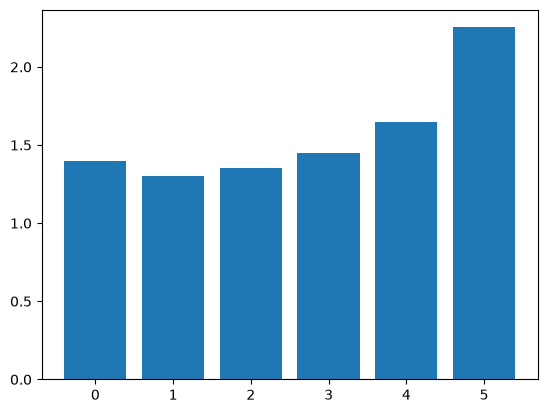

In [32]:
plt.bar([0,1,2,3,4,5], div_summary["mean"])

Pour tenter d'obtenir des conclusions plus significatives, nous allons calculer la corrélation de spearman de indice de diversité avec les avancées du mouvement. Mais puisque celle-ci suppose une indépendance des données, et que la base Navco 2.1 contient des ittérations du même mouvement social sur différentes années, qui ne sont à priori pas indépendantes les unes des autres, nous allons regrouper les observation par mouvement social. Il n'est pas dit que deux mouvements sociaux soient forcément indépendants, mais c'est une hypothèse moins forte que de dire qu'au sein d'un même mouvement social, deux années sont indépendantes.

Nous effectuons donc un groupby qui utilise le nom des mouvements sociaux, et prenons le max de chaque variable sur toutes les années ou il s'étend. Le maximum nous parraît être un bon indicateur des différents types de diversité (ie si une forme de diversité a été observée à une année d'un mouvement social, ce mouvement social est considéré comme présentant ce type de diversité). Nous utilisons également le maximum des avancées obtenues par le mouvement comm un indicateur du total des avancées. Cette approche a l'avantage de ne pas effectuer d'opérations sur des données ordinales, qui pourraient ne pas correctement prendre en compte les écarts entre les siituations représentées par ces variables, qui peuvent ne pas être reflétées par leur répartition numérique. Néanmoins, elle a pour inconvénient de rendre l'analyse un peu moins précise. On pourrait par exemple imagine qu'un mouvement obtient la majorité de ses avancées l'année où il présente sa diversité la plus faible, ou vice-versa, même si la corrélation positive observée jusqu'ici ne semble pas le suggérer.

In [16]:
navco_div_agg = navco_div_c.groupby("camp_name").max()

In [17]:
data = navco_div_agg[["indice_div", "progress"]]

rho, p_value = stats.spearmanr(
    data["indice_div"],
    data["progress"]
)
print("coéficient de corrélation de spearman: ", rho)
print("p-valeur: ", p_value)

coéficient de corrélation de spearman:  0.30156702254884515
p-valeur:  2.788099602909762e-09


Nous obtenons une corrélation de spearman d'environ 0.3 (un tout petit peu plus faible que la corrélation directe observée plus haut), qui conforte l'idée qu'il y aurait une corrélation positive mais assez faible entre la diversité sociale observée dans un mouvement et les résultats qu'il obtient. De plus, la p-valeur très faible (de l'ordre de 10^{-9}) semble indiquer que cette corrélation est très significative.

Nous allons maintenant nous intéresser à l'effet marginal de chaque type de diversité sur les résultats du mouvement. Pour cela, nous effectuons une régression ordinale de proigress sur toutes les autres variables de diversité.

In [9]:
diversite = navco_div_agg[["div_age", "div_class", "div_gender", "div_urban_rural", "div_ideology", "div_regional", "div_party", "div_ethnicity", "div_religion"]]
progress = navco_div_agg["progress"]

data = pd.concat([progress, diversite], axis=1)


model = stm.OrderedModel(data["progress"],data.drop(columns=["progress"]),distr="logit")

results = model.fit(method="bfgs")

results.summary()

Optimization terminated successfully.
         Current function value: 1.554891
         Iterations: 38
         Function evaluations: 39
         Gradient evaluations: 39


<class 'statsmodels.iolib.summary.Summary'>
"""
                             OrderedModel Results                             
==============================================================================
Dep. Variable:               progress   Log-Likelihood:                -579.97
Model:                   OrderedModel   AIC:                             1188.
Method:            Maximum Likelihood   BIC:                             1243.
Date:                Tue, 24 Nov 2026                                         
Time:                        16:34:24                                         
No. Observations:                 373                                         
Df Residuals:                     359                                         
Df Model:                           9                                         
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
div_age            -0.3396      0.285     -1.192      0.233      -0.898       0.219
div_class           0.9925      0.274      3.626      0.000       0.456       1.529
div_gender          0.1086      0.243      0.447      0.655      -0.368       0.585
div_urban_rural    -0.0598      0.251     -0.238      0.812      -0.552       0.432
div_ideology        0.2113      0.279      0.756      0.449      -0.336       0.759
div_regional       -0.1820      0.258     -0.706      0.480      -0.687       0.323
div_party           0.3400      0.276      1.230      0.219      -0.202       0.882
div_ethnicity       0.3439      0.224      1.535      0.125      -0.095       0.783
div_religion        0.2542      0.240      1.061      0.289      -0.215       0.724
0/1                -1.3011      0.240     -5.427      0.000      -1.771      -0.831
1/2                 0.2725      0.109      2.494      0.013       0.058       0.487
2/3                -0.8472      0.167     -5.066      0.000      -1.175      -0.519
3/4                -0.9677      0.170     -5.688      0.000      -1.301      -0.634
4/5                -0.6281      0.143     -4.388      0.000      -0.909      -0.348
===================================================================================
"""

On peut voir que les coéficients varient entre -0.33 et 1, bien que la plupart soient positifs. Néanmoins, les p-valeurs sont presque toutes assez élevées (> 0.10), ce qui semble signifier que le résultat n'est pas vraiment significatif. La diversité de classe sociale fait exception à la règle, avec une p-valeur très faible (< 0.001), qui semble indiquer un résultat assez significatif. Le coéficient presque égal à 1 suggère également un effet assez important. Un mouvement qui mobilise plusieurs classes sociales obtiendrait donc en moyenne des résultats plus importants

## Conclusion

Nous avons d’abord testé l’hypothèse des 3,5 % de Erica Chenoweth. Nous observons que la mobilisation de masse favorise le succès, mais sans effet de seuil absolu. Le taux de réussite augmente nettement avec le pic de participation mais la progression la plus forte s'opère dès les premiers paliers (autour de 0,5 % à 1 %) et se stabilise ensuite. De plus, presque 25 % des campagnes non-violentes ayant atteint ou dépassé 3,5 % ont échoué. Le seuil de 3,5 % améliore donc fortement les chances de succès mais sans constituer une garantie absolue. Nous ne voyons donc pas de raison de garder ce seuil comme une règle absolue.

La non-violence est un facteur déterminant. Les campagnes majoritairement non violentes réussissent presque deux fois plus souvent que les campagnes violentes (59 % contre 33 %, odds ratio = 0,33). Cette efficacité s'explique en partie par une capacité de mobilisation supérieure (pic médian de 0,75 % de la population contre 0,18 % pour les mouvements violents) mais aussi par d’autres facteurs.

Cet effet résiste à la nature des revendications. Bien que les objectifs les plus radicaux (sécession, opposition à une occupation) soient majoritairement portés par des mouvements violents, le contrôle par l'objectif initial (odds ratio ajusté = 0,34) montre qu'à revendication comparable, la non-violence conserve un avantage net.

Enfin, au sein des campagnes non violentes, la présence d'une frange radicale (dégâts matériels ou violences ponctuelles) n'entraîne pas de baisse statistiquement significative du taux de succès (59 % avec branche radicale contre 64 % sans).
